## BMDS554 – Machine Learning & Data Visualization
# Network Visualization Exercises

Here are two brief exercises for learning how to visualize graphs using iGraph:
* **Exercise 1:** Modify the Graph Layouts (5 minutes)
* **Exercise 2:** Adjust the Graph Encodings (10 mins)

**About iGraph**: [iGraph](https://igraph.org/) is a graph analytics and rendering tool. It is available across multiple languages, including Python.

In terms of performance, iGraph should provide reasonable performance when plotting graphs at a scale of ~1000 to ~10,000 nodes. It becomes considerably slower at the scale of ~100,000 nodes and higher. Our lab is still testing its performance.

**About the Dataset**: For these exercises, we will be using a graph dataset about plants and pollinators from the following paper (found via the [Web of Life](https://www.web-of-life.es/networkjson.php?id=M_PL_074_12) dataset archive):

Gonzalez, O. & Loiselle, B. A. (2016). Species interactions in an Andean bird–flowering plant network: phenology is more important than abundance or morphology. PeerJ, 4, e2789.
[https://doi.org/10.7717/peerj.2789](https://doi.org/10.7717/peerj.2789)

**iGraph Tutorial**: This [tutorial](https://igraph.org/python/versions/latest/visualisation.html) is very helpful for learning how to generate network visualizations using iGraph.

**Alternative Tools**: If you are interested in other Graph analysis/rendering tools as well, here are some options:
* [Plotly](https://plotly.com/python/network-graphs/) - mainly for visualization
* [NetworkX](https://networkx.org/documentation/stable/auto_examples/index.html) - mainly for graph analysis
* [Graph-tool](https://graph-tool.skewed.de/) -0but installing it is more involved than the other options)

In [2]:
import altair as alt
import igraph as ig
import matplotlib.pyplot as plt
import json
import os

In [7]:
with open(os.path.join("/home/kweku/philemon/data visualisation/network_exercises/network_exercises/","pollinator_network.json"),"r") as f:
    raw = json.load(f)

In [8]:
# convert data to the igraph structure
nodes = { # each variable must be its own list of values
    "nodeid": [int(x["nodeid"]) for x in raw["nodes"]],
    "name": [x["name"] for x in raw["nodes"]],
    "group": [x["group"] for x in raw["nodes"]],
    "fill": [x["fill"] for x in raw["nodes"]],
    "value": [x["value"] for x in raw["nodes"]]
}

# edges must be a list of tuples of the form (source, target)
edges = [(x["source"],x["target"]) for x in raw["links"]]

In [9]:
g = ig.Graph() # Create the iGraph graph object
g.add_vertices(nodes["nodeid"]) # add the nodes
for variable in list(nodes.keys()): # add the node variables
    g.vs[variable] = nodes[variable]
g.add_edges(edges) # add the edges

## Exercise 1: Modify the Graph Layouts (5 minutes)
Select three layout options from the iGraph [visualization tutorial](https://igraph.org/python/versions/latest/visualisation.html). Render them in this JupyterLab notebook. How much does the visualization change based on the layout?

Note that many layout algorithms may generate a different layout each time, unless you set a seed parameter. Run each code cell multiple times to see how the layout changes.

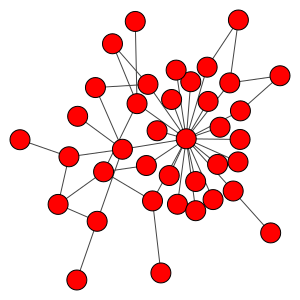

In [10]:
layout = g.layout("auto") # modify the layout here
ig.plot(g, layout=layout, bbox=(0, 0, 300, 300))

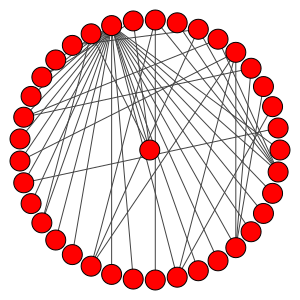

In [12]:
layout = g.layout("star") # modify the layout here
ig.plot(g, layout=layout, bbox=(0, 0, 300, 300))

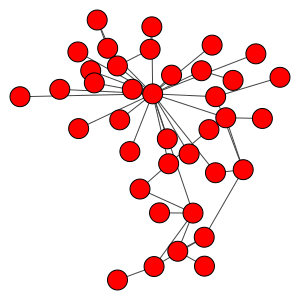

In [18]:
layout = g.layout("drl") # modify the layout here
ig.plot(g, layout=layout, bbox=(0, 0, 300, 300))

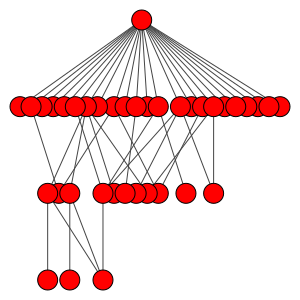

In [15]:
layout = g.layout("sugiyama") # modify the layout here
ig.plot(g, layout=layout, bbox=(0, 0, 300, 300))

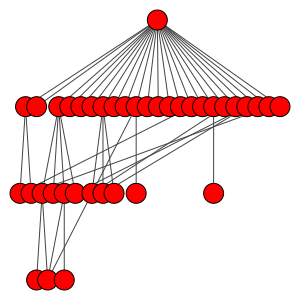

In [16]:
layout = g.layout("reingold_tilford") # modify the layout here
ig.plot(g, layout=layout, bbox=(0, 0, 300, 300))

## Exercise 2: Adjust the Graph Encodings (10 mins)
At the end of the [visualization tutorial](https://igraph.org/python/tutorial/0.9.6/visualisation.html), we see a number of options for adjusting the visual encodings for the nodes:
```
ig.plot(g,
        vertex_size=20,
        vertex_color=['blue', 'red', 'green', 'yellow'],
        vertex_label=['first', 'second', 'third', 'fourth'],
        edge_width=[1, 4],
        edge_color=['black', 'grey'],
        )
```

Copy your preferred solution for Exercise 1 as the starting code for Exercise 2. Use the above guidance to adjust the following properties of the graph:
* encode node `value` using `vertex_size` in the graph
* encode node `fill` using `vertex_color` in the graph (`fill` applies different colors for plants and pollinators, shown in the node's `group` variable)
* add the node `name` using `vertex_label`

**Optional**: Try changing other vertex properties. iGraph also includes other encoding channels, listed in their [R documentation](https://igraph.org/r/html/1.2.5/plot.common.html). Note that R properties with a "." in the R documentation are typically supported using "_" in Python (example: "vertex.label.color" in R becomes "vertex_label_color" in Python).

Note that you may also need to adjust the size of the visualization if you want to include labels.

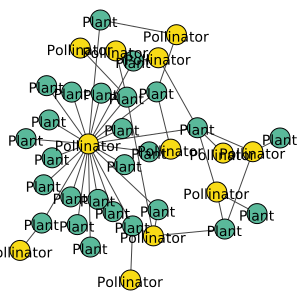

In [54]:
layout = g.layout("davidson_harel") # modify the layout here
ig.plot(g,
        layout=layout,
        vertex_size=20,
        vertex_color=nodes["fill"],
        # vertex_color=['blue', 'red', 'green', 'yellow'],
        vertex_label=nodes["group"],
        # vertex_label=['first', 'second', 'third', 'fourth'],
        # edge_width=[1, 4],
        # edge_color=['black', 'grey'],
        bbox=(0, 0, 300, 300)
        )